# PROJECT TITLE GOES HERE - BY: ZEBRA

# Installing geopandas 
For map and choropleth functionality

In [43]:
%pip install geopandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


# Importing Packages
Imports are organized and formatted according to Ruff linting guidelines.

In [44]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd


In [45]:
# Check that geopandas installed and what version was installed.
print(gpd.__version__)

1.2.0


In [46]:
# Load U.S. state boundary data from the Census Bureau
states = gpd.read_file(
    "https://www2.census.gov/geo/tiger/GENZ2024/shp/cb_2024_us_state_500k.zip"
)
# Preview the first five rows
print(states.head())

  STATEFP   STATENS      GEOIDFQ GEOID STUSPS          NAME LSAD  \
0      35  00897535  0400000US35    35     NM    New Mexico   00   
1      46  01785534  0400000US46    46     SD  South Dakota   00   
2      06  01779778  0400000US06    06     CA    California   00   
3      21  01779786  0400000US21    21     KY      Kentucky   00   
4      01  01779775  0400000US01    01     AL       Alabama   00   

          ALAND       AWATER  \
0  314198519809    726531289   
1  196341670967   3387563375   
2  403673433805  20291632828   
3  102266755818   2384136185   
4  131185561946   4581813708   

                                            geometry  
0  POLYGON ((-109.05017 31.48, -109.04984 31.4995...  
1  POLYGON ((-104.05788 44.9976, -104.05078 44.99...  
2  MULTIPOLYGON (((-118.60442 33.47855, -118.5987...  
3  MULTIPOLYGON (((-89.40565 36.52816, -89.39868 ...  
4  MULTIPOLYGON (((-88.05338 30.50699, -88.05109 ...  


## Load in the pandas dataframe. 

In [47]:
df = pd.read_csv("Race by State.csv", encoding="utf-8")

In [48]:
df.sample(5)

,Notes,States,States Code,Race,Race Code,Population
265,Total,Oregon,41.0,NaN,NaN,21271455.0
165,NaN,Minnesota,27.0,White,2106-3,23671188.0
52,NaN,Delaware,10.0,Native Hawaiian or Other Pacific Islander,NHOPI,6067.0
304,NaN,Texas,48.0,Native Hawaiian or Other Pacific Islander,NHOPI,243410.0
386,"sort by year, or select only one year.",NaN,NaN,NaN,NaN,NaN


In [49]:
df.head(10)

,Notes,States,States Code,Race,Race Code,Population
0,NaN,Alabama,1.0,American Indian or Alaska Native,1002-5,189858.0
1,NaN,Alabama,1.0,Asian,A,411086.0
2,NaN,Alabama,1.0,Black or African American,2054-5,6785631.0
3,NaN,Alabama,1.0,Native Hawaiian or Other Pacific Islander,NHOPI,30330.0
4,NaN,Alabama,1.0,White,2106-3,17520840.0
5,NaN,Alabama,1.0,More than one race,M,496098.0
6,Total,Alabama,1.0,NaN,NaN,25433843.0
7,NaN,Alaska,2.0,American Indian or Alaska Native,1002-5,573448.0
8,NaN,Alaska,2.0,Asian,A,250482.0
9,NaN,Alaska,2.0,Black or African American,2054-5,135645.0


## Now we are going to load in the combined dataset and try to visualize it.

In [50]:
df_comb=pd.read_csv("STATE_MMR_COMB_DATA.csv",encoding="UTF-8")

In [51]:
df_comb.head(10)

,State,STATE_MMR,BLACK_POP,BLACK_MMR,STRUCT_ RACISM_SCORE
0,Alabama,30.4,0.25,55.8,-1.13
1,Alaska,NaN,0.02,NaN,-1.27
2,Arizona,28.4,0.04,45.5,-0.66
3,Arkansas,32.7,0.14,72.1,-0.89
4,California,10.8,0.05,36.5,1.06
5,Colorado,16.0,0.04,NaN,0.83
6,Connecticut,14.4,0.10,NaN,2.04
7,Delaware,NaN,0.21,NaN,-0.44
8,Florida,22.7,0.14,49.8,-0.80
9,Georgia,28.5,0.30,51.3,-1.20


### Designating all rows and limit columns.

In [52]:
df_comb = df_comb.iloc[:,:5]

In [53]:
df_comb.head(10)

,State,STATE_MMR,BLACK_POP,BLACK_MMR,STRUCT_ RACISM_SCORE
0,Alabama,30.4,0.25,55.8,-1.13
1,Alaska,NaN,0.02,NaN,-1.27
2,Arizona,28.4,0.04,45.5,-0.66
3,Arkansas,32.7,0.14,72.1,-0.89
4,California,10.8,0.05,36.5,1.06
5,Colorado,16.0,0.04,NaN,0.83
6,Connecticut,14.4,0.10,NaN,2.04
7,Delaware,NaN,0.21,NaN,-0.44
8,Florida,22.7,0.14,49.8,-0.80
9,Georgia,28.5,0.30,51.3,-1.20


## Start descriptive Stats Visualization

In [54]:
df_sorted = df_comb.sort_values("BLACK_MMR", ascending=False)
df_topten = df_sorted.head(10)
df_topten

,State,STATE_MMR,BLACK_POP,BLACK_MMR,STRUCT_ RACISM_SCORE
15,Kansas,21.0,0.05,106.7,0.35
41,Tennessee,41.8,0.15,88.3,-0.93
29,New Jersey,24.8,0.12,78.8,2.22
35,Oklahoma,28.7,0.06,75.6,-0.90
3,Arkansas,32.7,0.14,72.1,-0.89
17,Louisiana,39.4,0.30,66.5,-0.74
39,South Carolina,30.3,0.24,66.4,-0.69
23,Mississippi,37.5,0.36,63.8,-1.17
32,North Carolina,28.6,0.20,62.8,-0.64
45,Virginia,32.4,0.18,61.8,-0.68


In [55]:
type(df_topten.loc[45,"BLACK_MMR"])

numpy.float64

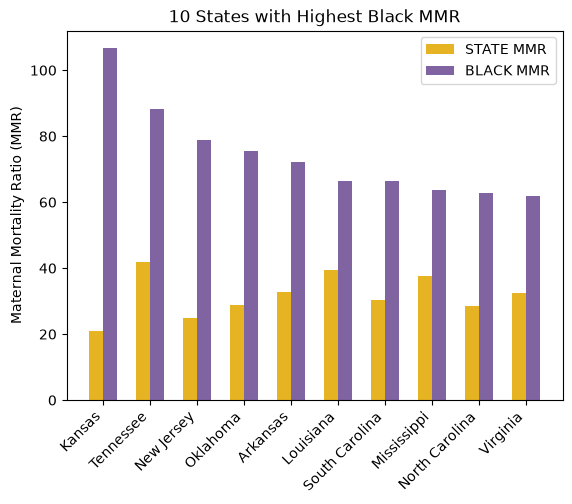

In [56]:
import numpy as np
# Top 10 States Black MMR
fig, ax = plt.subplots()
width = 0.3
x = np.arange(10)
y = ["BLACK_MMR","STATE_MMR"]
ax.bar(x-width/2, df_topten["STATE_MMR"], width, label = "STATE MMR", color="#E6B422")
ax.bar(x+width/2, df_topten["BLACK_MMR"], width, label = "BLACK MMR", color="#8064A2")
ax.set_xticks(x)
ax.set_xticklabels(df_topten["State"], rotation = 45, ha = "right")
ax.legend()
ax.set_ylabel("Maternal Mortality Ratio (MMR)")
ax.set_title("10 States with Highest Black MMR")
plt.show()

In [57]:
# Evaluating STATE_MMR_COMB_DATA.csv
# Check the columns in my maternal mortality dataset
print(df_comb.columns.tolist())
print(df_comb.head())

['State', 'STATE_MMR', 'BLACK_POP', 'BLACK_MMR', 'STRUCT_ RACISM_SCORE']
        State  STATE_MMR  BLACK_POP  BLACK_MMR  STRUCT_ RACISM_SCORE
0     Alabama       30.4       0.25       55.8                 -1.13
1      Alaska        NaN       0.02        NaN                 -1.27
2     Arizona       28.4       0.04       45.5                 -0.66
3    Arkansas       32.7       0.14       72.1                 -0.89
4  California       10.8       0.05       36.5                  1.06


In [58]:
# Merge maternal mortality data with U.S. state boundaries.

map_data = states.merge(
    df_comb,
    left_on = "NAME",
    right_on="State",
    how = "left"
)

# Check the merged dataset
print(map_data[["NAME", "STATE_MMR", "BLACK_MMR"]].head())

           NAME  STATE_MMR  BLACK_MMR
0    New Mexico       28.9        NaN
1  South Dakota       21.4        NaN
2    California       10.8       36.5
3      Kentucky       28.0       47.8
4       Alabama       30.4       55.8


In [59]:
df_comb[["State", "STATE_MMR"]].head(10)

,State,STATE_MMR
0,Alabama,30.4
1,Alaska,NaN
2,Arizona,28.4
3,Arkansas,32.7
4,California,10.8
5,Colorado,16.0
6,Connecticut,14.4
7,Delaware,NaN
8,Florida,22.7
9,Georgia,28.5


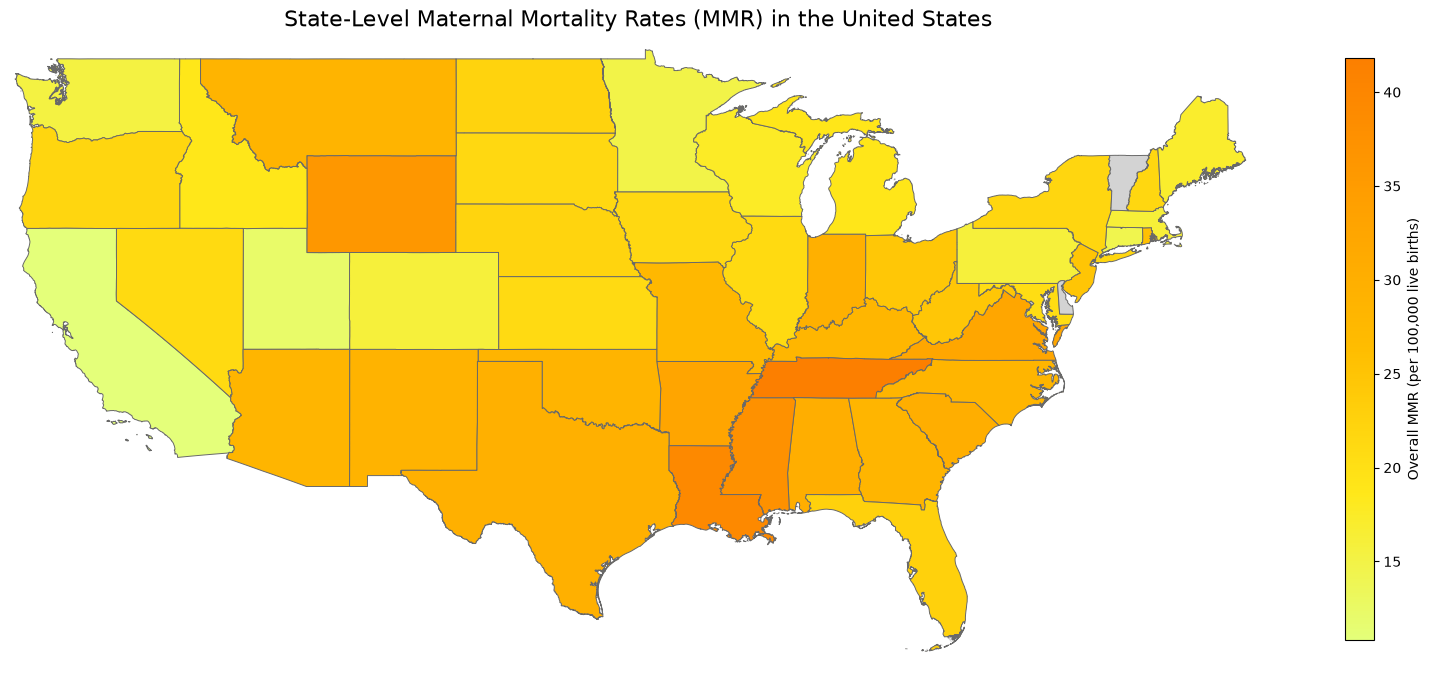

In [60]:
# Create a gold-gradient map of overall maternal mortality rates by state

fig, ax = plt.subplots(figsize = (16,10))

map_data.plot(
    column = "STATE_MMR",
    cmap ="Wistia",
    linewidth = 0.7,
    edgecolor ="dimgray",
    legend =True,
    missing_kwds = {
        "color": "lightgrey",
        "label": "No data"
    },
    legend_kwds={
        "label": "Overall MMR (per 100,000 live births)",
        "shrink": 0.6
    },
    ax=ax
)

ax.set_title(
    "State-Level Maternal Mortality Rates (MMR) in the United States",
    fontsize = 16
)


ax.set_xlim(-125, -66)
ax.set_ylim(24, 50)
ax.axis("off")
plt.tight_layout()
plt.show()

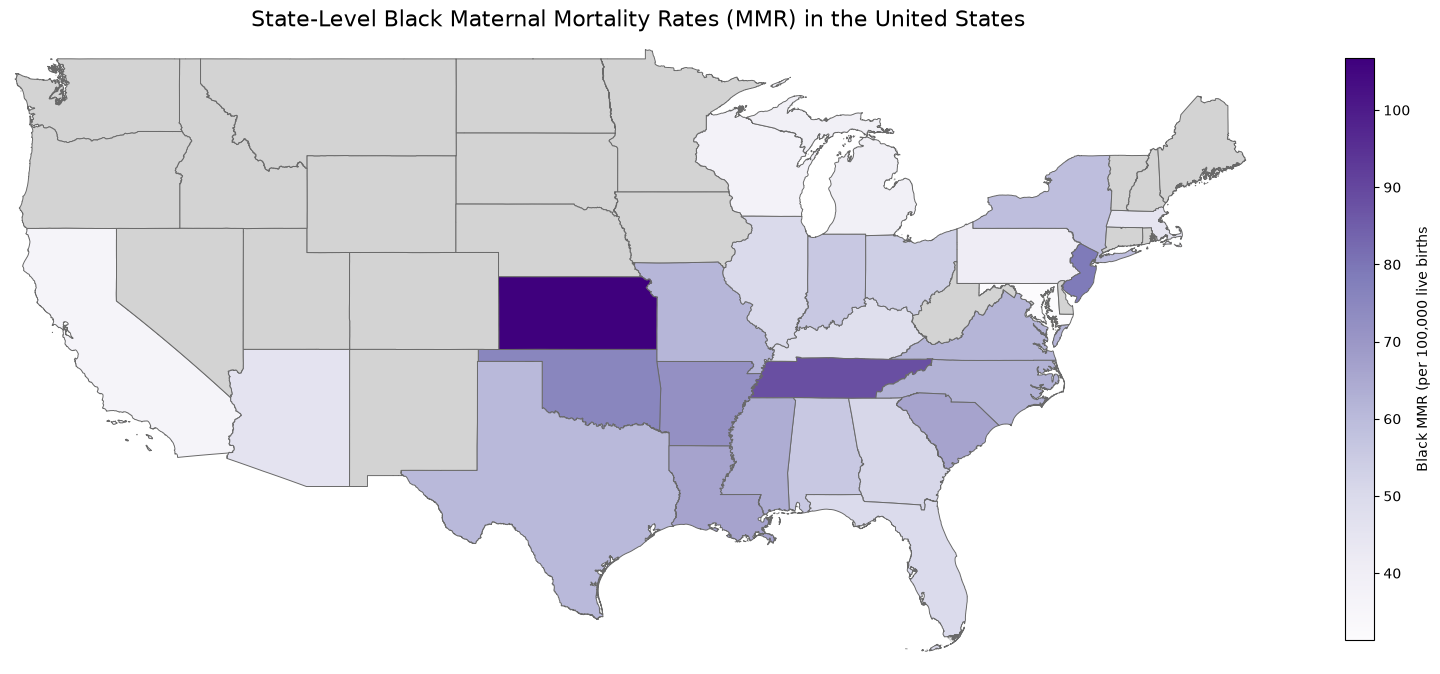

In [61]:
# Create a purple-gradient map of black maternal mortality rates by state

fig, ax = plt.subplots(figsize = (16,10))

map_data.plot(
    column = "BLACK_MMR",
    cmap ="Purples",
    linewidth = 0.7,
    edgecolor ="dimgray",
    legend =True,
    missing_kwds = {
        "color": "lightgrey",
        "label": "No data"
    },
    legend_kwds={
        "label": "Black MMR (per 100,000 live births",
        "shrink": 0.6
    },
    ax=ax
)

ax.set_title(
    "State-Level Black Maternal Mortality Rates (MMR) in the United States",
    fontsize = 16
)


ax.set_xlim(-125, -66)
ax.set_ylim(24, 50)
ax.axis("off")
plt.tight_layout()
plt.show()

# CDC Wonder Data Import

#Read CDC Wonder Datasets

In [62]:
# 1st the CDC Wonder Race Population Data 
# from Single-Race Population Estimates 2020-2024 by State and Single-Year Age Request 

race_population = pd.read_csv("race_population_2020-2024_state_cdc_wonder.csv", encoding="UTF-8")

race_population.head()

,Notes,States,States Code,Race,Race Code,Population
0,NaN,Alabama,1.0,American Indian or Alaska Native,1002-5,189858.0
1,NaN,Alabama,1.0,Asian,A,411086.0
2,NaN,Alabama,1.0,Black or African American,2054-5,6785631.0
3,NaN,Alabama,1.0,Native Hawaiian or Other Pacific Islander,NHOPI,30330.0
4,NaN,Alabama,1.0,White,2106-3,17520840.0


In [63]:
race_population.columns

Index(['Notes', 'States', 'States Code', 'Race', 'Race Code', 'Population'],
      dtype='str')

In [64]:
race_population.head(15)

,Notes,States,States Code,Race,Race Code,Population
0,NaN,Alabama,1.0,American Indian or Alaska Native,1002-5,189858.0
1,NaN,Alabama,1.0,Asian,A,411086.0
2,NaN,Alabama,1.0,Black or African American,2054-5,6785631.0
3,NaN,Alabama,1.0,Native Hawaiian or Other Pacific Islander,NHOPI,30330.0
4,NaN,Alabama,1.0,White,2106-3,17520840.0
5,NaN,Alabama,1.0,More than one race,M,496098.0
6,NaN,Alabama,1.0,Not Available,999,0.0
7,Total,Alabama,1.0,NaN,NaN,25433843.0
8,NaN,Alaska,2.0,American Indian or Alaska Native,1002-5,573448.0
9,NaN,Alaska,2.0,Asian,A,250482.0


In [65]:
black_population = race_population[
    race_population["Race"] == "Black or African American"
]

total_population = race_population[
    race_population["Notes"] == "Total"
]

print(black_population.head())
print(total_population.head())

   Notes      States  States Code                       Race Race Code  \
2    NaN     Alabama          1.0  Black or African American    2054-5   
10   NaN      Alaska          2.0  Black or African American    2054-5   
18   NaN     Arizona          4.0  Black or African American    2054-5   
26   NaN    Arkansas          5.0  Black or African American    2054-5   
34   NaN  California          6.0  Black or African American    2054-5   

    Population  
2    6785631.0  
10    135645.0  
18   2071490.0  
26   2386445.0  
34  12713540.0  
    Notes      States  States Code Race Race Code   Population
7   Total     Alabama          1.0  NaN       NaN   25433843.0
15  Total      Alaska          2.0  NaN       NaN    3678522.0
23  Total     Arizona          4.0  NaN       NaN   36894190.0
31  Total    Arkansas          5.0  NaN       NaN   15246937.0
39  Total  California          6.0  NaN       NaN  196436893.0


In [66]:
# Calculate the proportion of each state's population that is Black or African American.
black_pop = black_population[["States", "Population"]].merge(
    total_population[["States", "Population"]],
    on="States",
    suffixes=("_Black", "_Total")
)

black_pop["BLACK_POP"] = (
    black_pop["Population_Black"] / black_pop["Population_Total"]
)

black_pop.head()

,States,Population_Black,Population_Total,BLACK_POP
0,Alabama,6785631.0,25433843.0,0.266795
1,Alaska,135645.0,3678522.0,0.036875
2,Arizona,2071490.0,36894190.0,0.056147
3,Arkansas,2386445.0,15246937.0,0.156520
4,California,12713540.0,196436893.0,0.064721


In [67]:
black_pop.shape

(51, 4)

In [68]:
#Why is it 51 instead of 50, Lets see if there is DC included.
black_pop["States"].tail()

46         Virginia
47       Washington
48    West Virginia
49        Wisconsin
50          Wyoming
Name: States, dtype: str

In [69]:
black_pop["States"].head()

0       Alabama
1        Alaska
2       Arizona
3      Arkansas
4    California
Name: States, dtype: str

In [70]:
# Found DC
black_pop[~black_pop["States"].isin(df_comb["State"])]["States"]

8    District of Columbia
Name: States, dtype: str

In [71]:
#Remove DC
black_pop = black_pop[
    black_pop["States"] != "District of Columbia"
]

black_pop.shape

(50, 4)

In [72]:
#Compare to combined dataset
comparison = df_comb[["State", "BLACK_POP"]].merge(
    black_pop[["States", "BLACK_POP"]],
    left_on="State",
    right_on="States",
    suffixes=("_old","_new")

)

comparison.head(10)

,State,BLACK_POP_old,States,BLACK_POP_new
0,Alabama,0.25,Alabama,0.266795
1,Alaska,0.02,Alaska,0.036875
2,Arizona,0.04,Arizona,0.056147
3,Arkansas,0.14,Arkansas,0.156520
4,California,0.05,California,0.064721
5,Colorado,0.04,Colorado,0.047754
6,Connecticut,0.10,Connecticut,0.129046
7,Delaware,0.21,Delaware,0.237928
8,Florida,0.14,Florida,0.169789
9,Georgia,0.30,Georgia,0.330064


In [73]:
# Then the next dataset from CDC wonder MMR Cause of Death

df_wonder = pd.read_csv("mmr_research_by_state.csv", encoding="UTF-8")

In [74]:
df_wonder.head(10)

,Notes,Year,Year Code,State,State Code,Single Race 6,Single Race 6 Code,Education,Education Code,ICD-10 113 Cause List,ICD-10 113 Cause List Code,Deaths,Population,Crude Rate,Crude Rate Lower 95% Confidence Interval,Crude Rate Upper 95% Confidence Interval
0,NaN,2024.0,2024.0,Alabama,1.0,American Indian or Alaska Native,1002-5,8th grade or less,1.0,"#Pregnancy, childbirth and the puerperium (O00...",GR113-105,0.0,Not Applicable,Not Applicable,Not Applicable,Not Applicable
1,NaN,2024.0,2024.0,Alabama,1.0,American Indian or Alaska Native,1002-5,8th grade or less,1.0,Pregnancy with abortive outcome (O00-O07),GR113-106,0.0,Not Applicable,Not Applicable,Not Applicable,Not Applicable
2,NaN,2024.0,2024.0,Alabama,1.0,American Indian or Alaska Native,1002-5,8th grade or less,1.0,"Other complications of pregnancy, childbirth a...",GR113-107,0.0,Not Applicable,Not Applicable,Not Applicable,Not Applicable
3,NaN,2024.0,2024.0,Alabama,1.0,American Indian or Alaska Native,1002-5,9th through 12th grade with no diploma,2.0,"#Pregnancy, childbirth and the puerperium (O00...",GR113-105,0.0,Not Applicable,Not Applicable,Not Applicable,Not Applicable
4,NaN,2024.0,2024.0,Alabama,1.0,American Indian or Alaska Native,1002-5,9th through 12th grade with no diploma,2.0,Pregnancy with abortive outcome (O00-O07),GR113-106,0.0,Not Applicable,Not Applicable,Not Applicable,Not Applicable
5,NaN,2024.0,2024.0,Alabama,1.0,American Indian or Alaska Native,1002-5,9th through 12th grade with no diploma,2.0,"Other complications of pregnancy, childbirth a...",GR113-107,0.0,Not Applicable,Not Applicable,Not Applicable,Not Applicable
6,NaN,2024.0,2024.0,Alabama,1.0,American Indian or Alaska Native,1002-5,High school graduate or GED completed,3.0,"#Pregnancy, childbirth and the puerperium (O00...",GR113-105,0.0,Not Applicable,Not Applicable,Not Applicable,Not Applicable
7,NaN,2024.0,2024.0,Alabama,1.0,American Indian or Alaska Native,1002-5,High school graduate or GED completed,3.0,Pregnancy with abortive outcome (O00-O07),GR113-106,0.0,Not Applicable,Not Applicable,Not Applicable,Not Applicable
8,NaN,2024.0,2024.0,Alabama,1.0,American Indian or Alaska Native,1002-5,High school graduate or GED completed,3.0,"Other complications of pregnancy, childbirth a...",GR113-107,0.0,Not Applicable,Not Applicable,Not Applicable,Not Applicable
9,NaN,2024.0,2024.0,Alabama,1.0,American Indian or Alaska Native,1002-5,"Some college credit, but not a degree.",4.0,"#Pregnancy, childbirth and the puerperium (O00...",GR113-105,0.0,Not Applicable,Not Applicable,Not Applicable,Not Applicable


In [79]:
# Merge CDC Wonder Population data with state map boundaries
population_map = states.merge(
        black_pop,
        left_on="NAME",
        right_on="States",
        how="left"
)

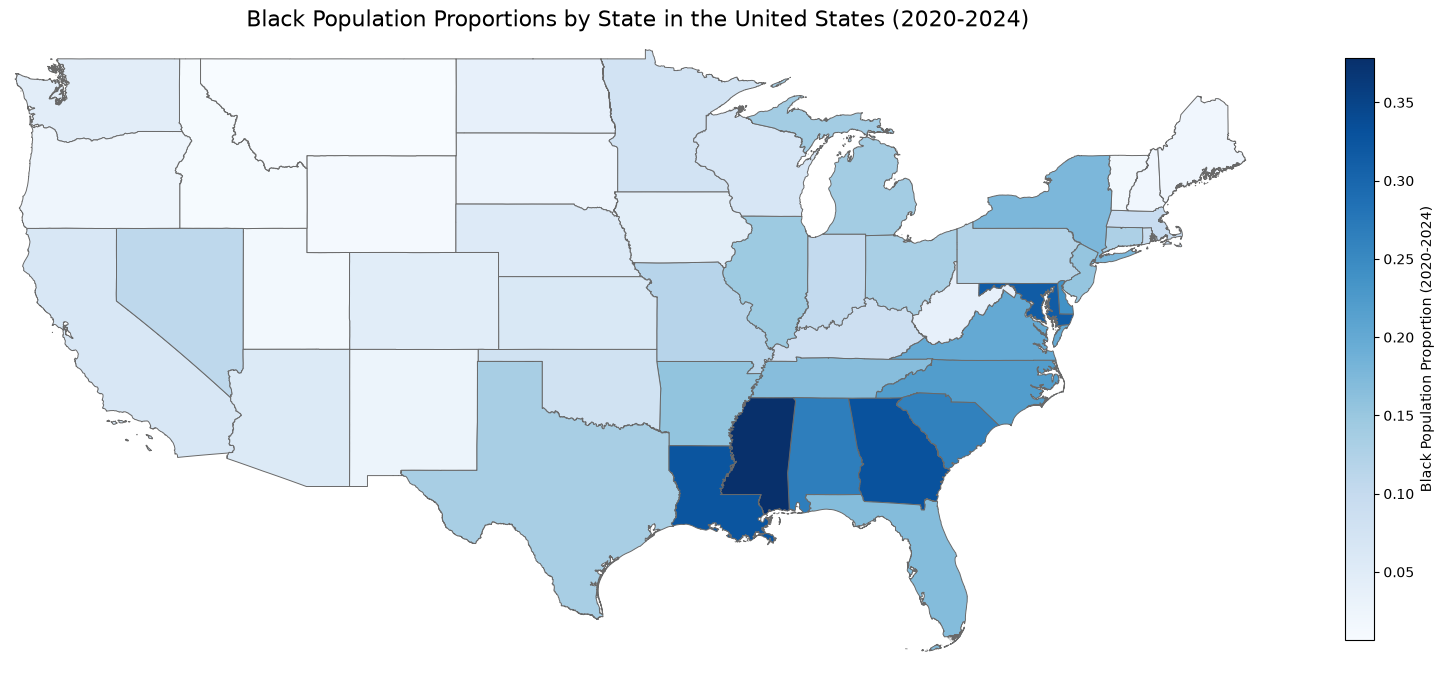

In [80]:
# Create a navy-gradient map of black population proportion by state

fig, ax = plt.subplots(figsize = (16,10))

population_map.plot(
    column = "BLACK_POP",
    cmap ="Blues",
    linewidth = 0.7,
    edgecolor ="dimgray",
    legend =True,
    missing_kwds = {
        "color": "lightgrey",
        "label": "No data"
    },
    legend_kwds={
        "label": "Black Population Proportion (2020-2024)",
        "shrink": 0.6
    },
    ax=ax
)

ax.set_title(
    "Black Population Proportions by State in the United States (2020-2024)",
    fontsize = 16
)


ax.set_xlim(-125, -66)
ax.set_ylim(24, 50)
ax.axis("off")
plt.tight_layout()
plt.show()

In [83]:
# 3. Import CDC Wonder Natality and Edcuation Data set 2022-2024 Black non hispanic
natality_education = pd.read_csv(
    "natality_education_cdc_wonder_2022-2024.csv",
    encoding="UTF-8"
)

natality_education.head()
natality_education.columns

# Check maternal education categories
natality_education["Mother's Education"].value_counts()

Mother's Education
High school graduate or GED completed                                  1815
Some college credit, but not a degree                                  1781
Bachelor's degree (BA, AB, BS)                                         1712
Associate degree (AA, AS)                                              1491
Master's degree (MA, MS, MEng, MEd, MSW, MBA)                          1364
9th through 12th grade with no diploma                                 1334
Doctorate (PhD, EdD) or Professional Degree (MD, DDS, DVM, LLB, JD)     955
8th grade or less                                                       852
Unknown or Not Stated                                                   477
Name: count, dtype: int64

In [84]:
# Filter for Black, non-Hispanic mothers
black_moms = natality_education[
    (natality_education["Mother's Single Race 6"] == "Black or African American") &
    (natality_education["Mother's Hispanic Origin"] == "Not Hispanic or Latino")
]

black_moms.head()

,Notes,State of Residence,State of Residence Code,Mother's Education,Mother's Education Code,Father's Education,Father's Education Code,Mother's Single Race 6,Mother's Single Race 6 Code,Mother's Hispanic Origin,Mother's Hispanic Origin Code,Births
1,NaN,Alabama,1.0,8th grade or less,1,8th grade or less,1,Black or African American,2054-5,Not Hispanic or Latino,2186-5,121.0
4,NaN,Alabama,1.0,8th grade or less,1,9th through 12th grade with no diploma,2,Black or African American,2054-5,Not Hispanic or Latino,2186-5,55.0
6,NaN,Alabama,1.0,8th grade or less,1,High school graduate or GED completed,3,Black or African American,2054-5,Not Hispanic or Latino,2186-5,50.0
10,NaN,Alabama,1.0,8th grade or less,1,Unknown or Not Stated,Unk,Black or African American,2054-5,Not Hispanic or Latino,2186-5,168.0
13,NaN,Alabama,1.0,9th through 12th grade with no diploma,2,8th grade or less,1,Black or African American,2054-5,Not Hispanic or Latino,2186-5,39.0


In [85]:
# Check education categories for Black mothers
black_moms["Mother's Education"].value_counts()

Mother's Education
High school graduate or GED completed                                  381
Some college credit, but not a degree                                  381
Bachelor's degree (BA, AB, BS)                                         378
Associate degree (AA, AS)                                              337
Master's degree (MA, MS, MEng, MEd, MSW, MBA)                          315
9th through 12th grade with no diploma                                 295
8th grade or less                                                      237
Doctorate (PhD, EdD) or Professional Degree (MD, DDS, DVM, LLB, JD)    218
Unknown or Not Stated                                                  119
Name: count, dtype: int64

In [86]:
# Calculate births to Black mother's with a bachelor's degree or higher
college_categories = [
    "Bachelor's degree (BA, AB, BS)",
    "Master's degree (MA, MS, MEng, Med, MSW, MBA)",
    "Doctorate (PhD, EdD) or Professional Degree (MD, DDS, DVM, LLB, JD)"
]

# Convert birth counts to numbers
black_moms["Births"] = pd.to_numeric(
    black_moms["Births"].astype(str).str.replace(",", ""),
    errors="coerce"
)

# Calculate percentage by state
education_by_state = black_moms[
    black_moms["Mother's Education"] != "Unknown or Not Stated"
].groupby("State of Residence")["Births"].sum().reset_index()

college_by_state = black_moms[
    black_moms["Mother's Education"].isin(college_categories)
].groupby("State of Residence")["Births"].sum().reset_index()

education_by_state = education_by_state.merge(
    college_by_state,
    on="State of Residence",
    suffixes=("_Total", "_College")
)

education_by_state["BLACK_BA_PLUS"] = (
    education_by_state["Births_College"] /
    education_by_state["Births_Total"] * 100
)

education_by_state.head()


,State of Residence,Births_Total,Births_College,BLACK_BA_PLUS
0,Alabama,46208.0,4628.0,10.015582
1,Alaska,516.0,89.0,17.248062
2,Arizona,13004.0,1963.0,15.095355
3,Arkansas,17874.0,1604.0,8.973929
4,California,51978.0,9589.0,18.448190


In [89]:
# Fill in Black maternal education percentages
education_lookup = education_by_state.set_index("State of Residence")["BLACK_BA_PLUS"]

df_comb["BLACK_BA_PLUS_PCT"] = df_comb["State"].map(education_lookup)

df_comb.head()

,State,STATE_MMR,BLACK_POP,BLACK_MMR,STRUCT_ RACISM_SCORE,BLACK_BA_PLUS_PCT
0,Alabama,30.4,0.25,55.8,-1.13,10.015582
1,Alaska,NaN,0.02,NaN,-1.27,17.248062
2,Arizona,28.4,0.04,45.5,-0.66,15.095355
3,Arkansas,32.7,0.14,72.1,-0.89,8.973929
4,California,10.8,0.05,36.5,1.06,18.448190


In [90]:
df_comb.columns

Index(['State', 'STATE_MMR', 'BLACK_POP', 'BLACK_MMR', 'STRUCT_ RACISM_SCORE',
       'BLACK_BA_PLUS_PCT'],
      dtype='str')

In [91]:
df_comb.to_csv("STATE_MMR_COMB_DATA.csv", index=False)

In [92]:
# Merge education data with state map bouandaries
education_map = states.merge(
    df_comb,
    left_on="NAME",
    right_on="State",
    how="left"
)

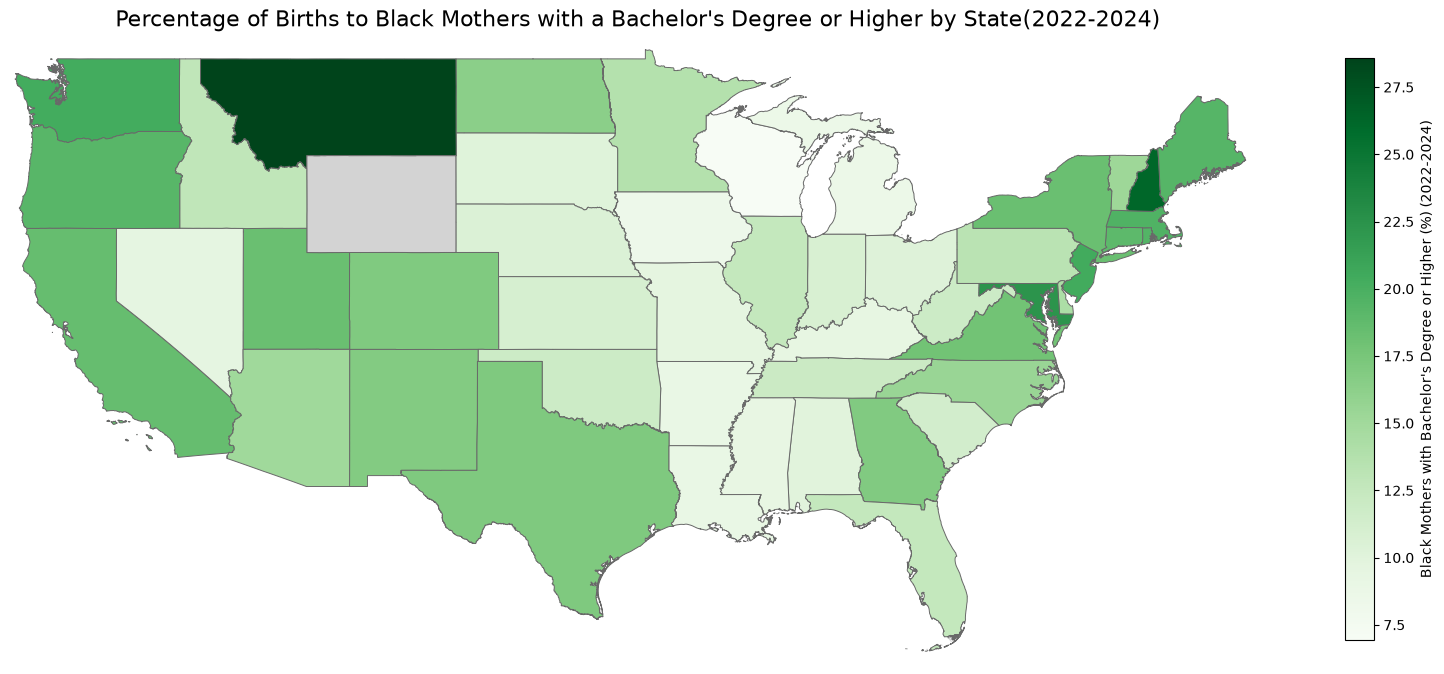

In [95]:
# Create a green-gradient map of Black Maternal Education by state

fig, ax = plt.subplots(figsize = (16,10))

education_map.plot(
    column = "BLACK_BA_PLUS_PCT",
    cmap ="Greens",
    linewidth = 0.7,
    edgecolor ="dimgray",
    legend =True,
    missing_kwds = {
        "color": "lightgrey",
        "label": "No data"
    },
    legend_kwds={
        "label": "Black Mothers with Bachelor's Degree or Higher (%) (2022-2024)",
        "shrink": 0.6
    },
    ax=ax
)

ax.set_title(
    "Percentage of Births to Black Mothers with a Bachelor's Degree or Higher by State(2022-2024)",
    fontsize = 16
)


ax.set_xlim(-125, -66)
ax.set_ylim(24, 50)
ax.axis("off")
plt.tight_layout()
plt.show()

# Generate Logo for Future Directions / Recommendations Section
Creating an SVG version of the MomCare logo.

In [78]:

# Define the project folder
logo_folder = Path.cwd()

# Define the output SVG file
svg_file = logo_folder / "MomCare_Logo.svg"

# Create the SVG canvas
svg = '''<svg xmlns="http://www.w3.org/2000/svg"
width="1000"
height="700"
viewBox="0 0 1000 700">

</svg>
'''

# Save the SVG file
svg_file.write_text(svg, encoding="utf-8")


98